# 02 - SQL EDA (DuckDB)

Descriptive churn cuts only. Every number comes from a `.sql` file in `sql/` that queries
`data/raw/Churn_Modelling.csv` directly; this notebook just runs them, shows the tables and plots the main cuts.
Identifiers (RowNumber, CustomerId, Surname) are dropped in `sql/00_base_view.sql`, which also defines every band once.

**Reading the charts.** Dashed line = overall churn rate. Hatched bars = fewer than 100 customers, so the rate is unreliable
(at n=100 the 95% interval is roughly +/-8 points or wider). Each x label shows the segment size.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
os.chdir(root)  # the SQL files use paths relative to the repo root

con = duckdb.connect()
con.execute((root / "sql" / "00_base_view.sql").read_text())


def run_sql(name):
    df = con.execute((root / "sql" / name).read_text()).df()
    for c in ("customers", "churners"):
        if c in df:
            df[c] = df[c].astype(int)
    return df


n_total, n_churn = con.execute("select count(*), sum(Exited) from customers").fetchone()
OVERALL = 100 * n_churn / n_total
LOW_N = 100

INK, MUTED, BAR, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#e6e5e1"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10})


def bar_panel(ax, d, title, value="churn_rate_pct", ref=None, ymax=None):
    x = np.arange(len(d))
    vals = d[value].fillna(0).to_numpy()
    for i, (v, n) in enumerate(zip(vals, d["customers"])):
        low = n < LOW_N
        ax.bar(i, v, width=0.6, color=BAR, hatch="////" if low else None, edgecolor="white", linewidth=0)
        ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", color=INK, fontsize=9)
    if ref is not None:
        ax.axhline(ref, color=MUTED, lw=1, ls="--")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{s}\nn={n:,}" for s, n in zip(d["segment"], d["customers"])], fontsize=8.5, color=MUTED)
    ax.set_ylim(0, ymax or vals.max() * 1.18)
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="y", colors=MUTED, length=0)
    ax.tick_params(axis="x", length=0)


def panels(df, dims, value="churn_rate_pct", ref=None, ncols=2, shared_max=False, suptitle=None):
    nrows = -(-len(dims) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.6 * nrows), constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    ymax = df[df["dimension"].isin(dims)][value].max() * 1.18 if shared_max else None
    for ax, dim in zip(axes, dims):
        bar_panel(ax, df[df["dimension"] == dim], dim, value, ref, ymax)
    for ax in axes[len(dims):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", color=INK, fontsize=12)
    plt.show()


print(f"{n_total:,} customers, {n_churn:,} churned -> overall churn rate {OVERALL:.2f}%")

10,000 customers, 2,037 churned -> overall churn rate 20.37%


## 1. Customer lever
Geography, Gender, age band (18-29 / 30-39 / 40-49 / 50-59 / 60+) and credit score band.
Credit bands follow FICO-style cut points (580 / 670 / 740 / 800), with the lowest range split at 500 so it is not one huge bucket.

,dimension,segment,customers,churners,churn_rate_pct
0,Age band,18-29,1641,124,7.6
1,Age band,30-39,4346,473,10.9
2,Age band,40-49,2618,806,30.8
3,Age band,50-59,869,487,56.0
4,Age band,60+,526,147,27.9
5,Credit score band,<500,632,150,23.7
6,Credit score band,500-579,1730,370,21.4
7,Credit score band,580-669,3331,685,20.6
8,Credit score band,670-739,2428,452,18.6
9,Credit score band,740-799,1224,252,20.6


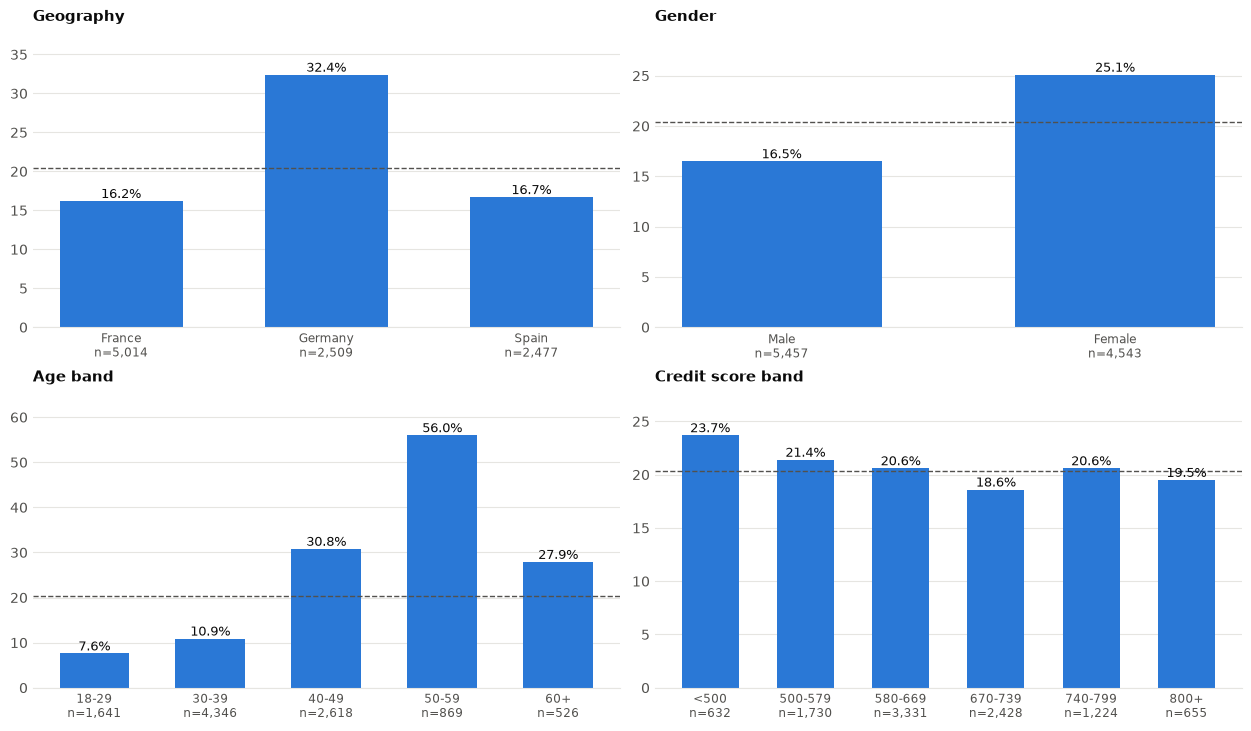

In [2]:
cust = run_sql("01_customer_lever.sql")
display(cust.drop(columns=["lever", "sort_key"]))
panels(cust, ["Geography", "Gender", "Age band", "Credit score band"], ref=OVERALL)

## 2. Product lever
Number of products, credit card, zero vs non-zero balance, and balance band.

,dimension,segment,customers,churners,churn_rate_pct
0,Balance band,Zero,3617,500,13.8
1,Balance band,1-100k,1584,326,20.6
2,Balance band,100-125k,2068,558,27.0
3,Balance band,125-150k,1762,429,24.3
4,Balance band,150k+,969,224,23.1
5,Credit card,Has credit card,7055,1424,20.2
6,Credit card,No credit card,2945,613,20.8
7,Number of products,1,5084,1409,27.7
8,Number of products,2,4590,348,7.6
9,Number of products,3,266,220,82.7


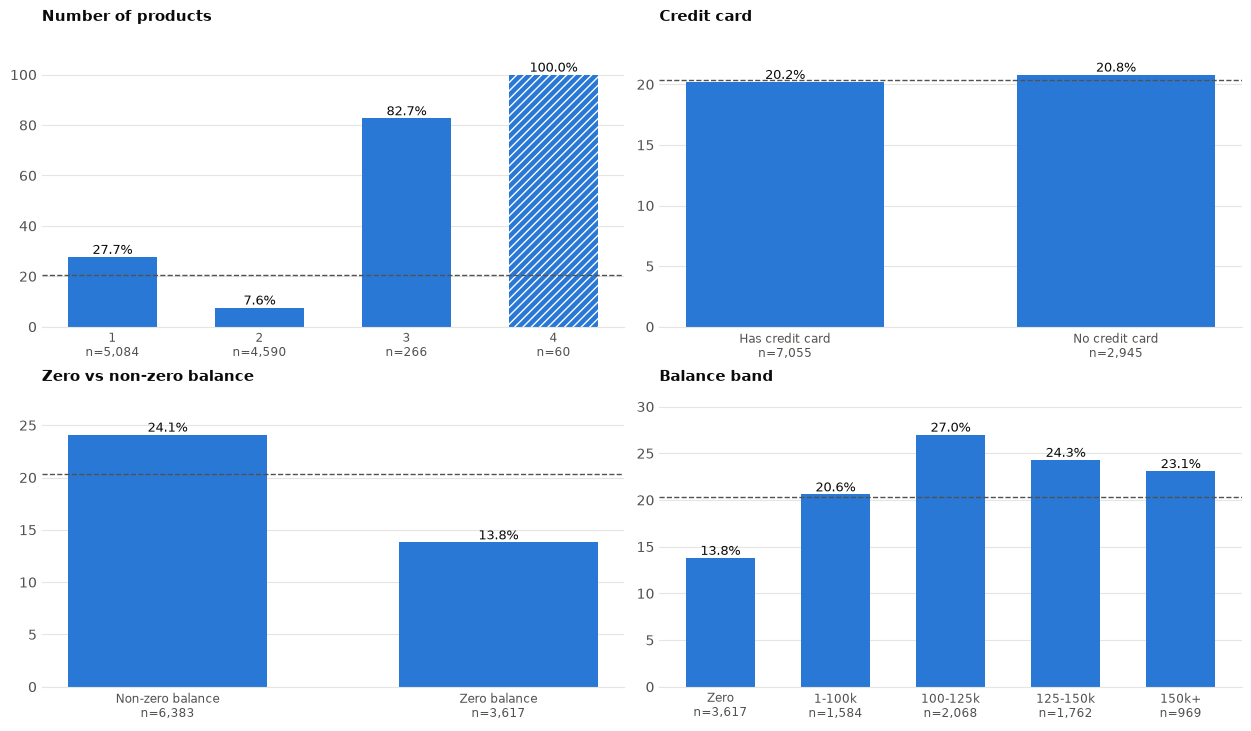

In [3]:
prod = run_sql("02_product_lever.sql")
display(prod.drop(columns=["lever", "sort_key"]))
panels(prod, ["Number of products", "Credit card", "Zero vs non-zero balance", "Balance band"], ref=OVERALL)

## 3. Engagement lever
Active member flag and tenure band (0-2 / 3-5 / 6-8 / 9-10 years).

,dimension,segment,customers,churners,churn_rate_pct
0,Active member,Active,5151,735,14.3
1,Active member,Inactive,4849,1302,26.9
2,Tenure band,0-2 yrs,2496,528,21.2
3,Tenure band,3-5 yrs,3010,625,20.8
4,Tenure band,6-8 yrs,3020,570,18.9
5,Tenure band,9-10 yrs,1474,314,21.3


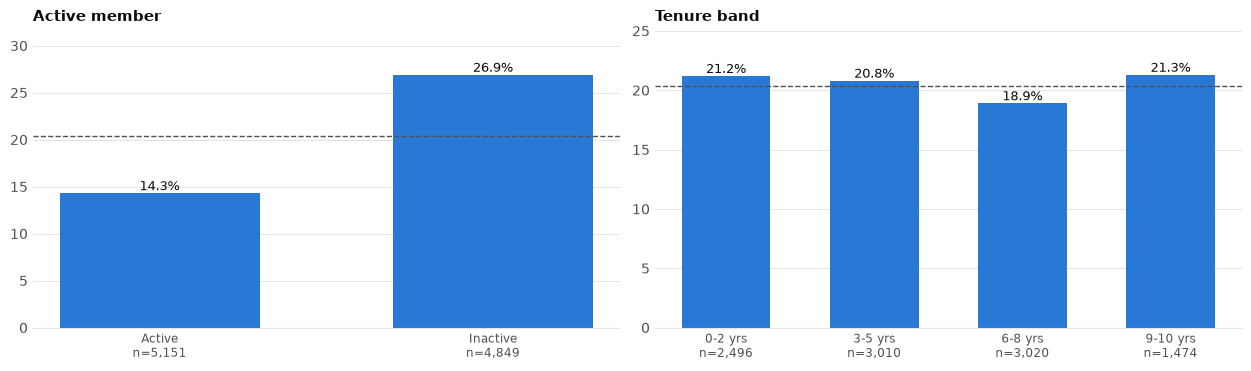

In [4]:
eng = run_sql("03_engagement_lever.sql")
display(eng.drop(columns=["lever", "sort_key"]))
panels(eng, ["Active member", "Tenure band"], ref=OVERALL)

## 4. Two-way cuts
Cells show churn rate, then customer counts underneath. Blank (-) means no customers in that cell.

In [5]:
def show_pivot(df, row, col, title):
    rate = df.pivot(index=row, columns=col, values="churn_rate_pct")
    n = df.pivot(index=row, columns=col, values="customers")
    print(title)
    display(rate.style.format("{:.1f}%", na_rep="-").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=100))
    display(n.style.format("{:,.0f}", na_rep="-"))


geo_act = run_sql("04_geography_x_activity.sql")
age_prod = run_sql("05_ageband_x_products.sql")
geo_zero = run_sql("06_geography_x_zero_balance.sql")

show_pivot(geo_act, "Geography", "activity_label", "Geography x active member")
show_pivot(age_prod, "age_band", "products", "Age band x number of products (3 and 4 pooled as '3-4')")
show_pivot(geo_zero, "Geography", "balance_flag", "Geography x zero vs non-zero balance")

Geography x active member


activity_label,Active,Inactive
Geography,,
France,11.5%,21.1%
Germany,23.7%,41.1%
Spain,10.7%,23.3%


activity_label,Active,Inactive
Geography,,
France,"2,591","2,423"
Germany,"1,248","1,261"
Spain,"1,312","1,165"


Age band x number of products (3 and 4 pooled as '3-4')


products,1,2,3-4
age_band,,,
18-29,10.9%,2.9%,63.0%
30-39,15.2%,4.2%,75.0%
40-49,40.1%,11.8%,91.9%
50-59,64.1%,28.5%,98.6%
60+,34.7%,13.3%,82.6%


products,1,2,3-4
age_band,,,
18-29,755,859,27
30-39,"2,098","2,164",84
40-49,"1,409","1,086",123
50-59,537,263,69
60+,285,218,23


Geography x zero vs non-zero balance


balance_flag,Non-zero balance,Zero balance
Geography,,
France,18.2%,13.9%
Germany,32.4%,-
Spain,19.6%,13.6%


balance_flag,Non-zero balance,Zero balance
Geography,,
France,"2,596","2,418"
Germany,"2,509",-
Spain,"1,278","1,199"


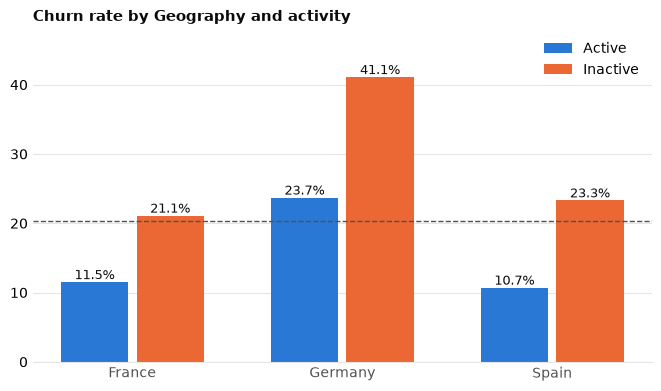

In [6]:
# Grouped bars for the one two-way cut with two series: Geography x active member
fig, ax = plt.subplots(figsize=(6.5, 3.8), constrained_layout=True)
colors = {"Active": "#2a78d6", "Inactive": "#eb6834"}
geos = list(geo_act["Geography"].unique())
w = 0.36
for j, grp in enumerate(["Active", "Inactive"]):
    d = geo_act[geo_act["activity_label"] == grp].set_index("Geography").loc[geos]
    xs = np.arange(len(geos)) + (j - 0.5) * w
    ax.bar(xs, d["churn_rate_pct"], width=w - 0.04, color=colors[grp], label=grp)
    for x_, v, n in zip(xs, d["churn_rate_pct"], d["customers"]):
        ax.text(x_, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.axhline(OVERALL, color=MUTED, lw=1, ls="--")
ax.set_xticks(np.arange(len(geos)))
ax.set_xticklabels(geos, color=MUTED)
ax.set_ylim(0, 48)
ax.set_title("Churn rate by Geography and activity", loc="left", color=INK, fontsize=11, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID); ax.tick_params(length=0)
plt.show()

## 5. Balance at risk
Total balance held by customers who churned, by segment.
`pct_of_segment_balance` = churned balance / that segment's balance. `share_of_total_balance` = churned balance / the bank's total balance.
Within one dimension the segments add up to the overall figure, so the bars below are directly comparable.
Balances are in the dataset's own units.

In [7]:
bar = run_sql("07_balance_at_risk.sql")
for c in ("segment_balance", "churned_balance"):
    bar[c] = bar[c] / 1e6
bar = bar.rename(columns={"segment_balance": "segment_balance_M", "churned_balance": "churned_balance_M"})
display(bar.drop(columns=["sort_key"]).round(1))
overall = bar[bar["dimension"] == "Overall"].iloc[0]
print(f"Total balance {overall.segment_balance_M:,.1f}M; held by churned customers {overall.churned_balance_M:,.1f}M "
      f"= {overall.share_of_total_balance:.1f}% of all balance (vs {OVERALL:.1f}% of customers).")

,dimension,segment,customers,churners,segment_balance_M,churned_balance_M,pct_of_segment_balance,share_of_total_balance
0,Overall,All customers,10000,2037,764.9,185.6,24.3,24.3
1,Active member,Active,5151,735,390.8,67.1,17.2,8.8
2,Active member,Inactive,4849,1302,374.0,118.5,31.7,15.5
3,Age band,18-29,1641,124,120.9,12.4,10.3,1.6
4,Age band,30-39,4346,473,326.3,43.2,13.2,5.6
5,Age band,40-49,2618,806,205.5,72.9,35.5,9.5
6,Age band,50-59,869,487,72.7,43.6,59.9,5.7
7,Age band,60+,526,147,39.5,13.5,34.2,1.8
8,Balance band,Zero,3617,500,0.0,0.0,NaN,0.0
9,Balance band,1-100k,1584,326,129.5,26.1,20.2,3.4


Total balance 764.9M; held by churned customers 185.6M = 24.3% of all balance (vs 20.4% of customers).


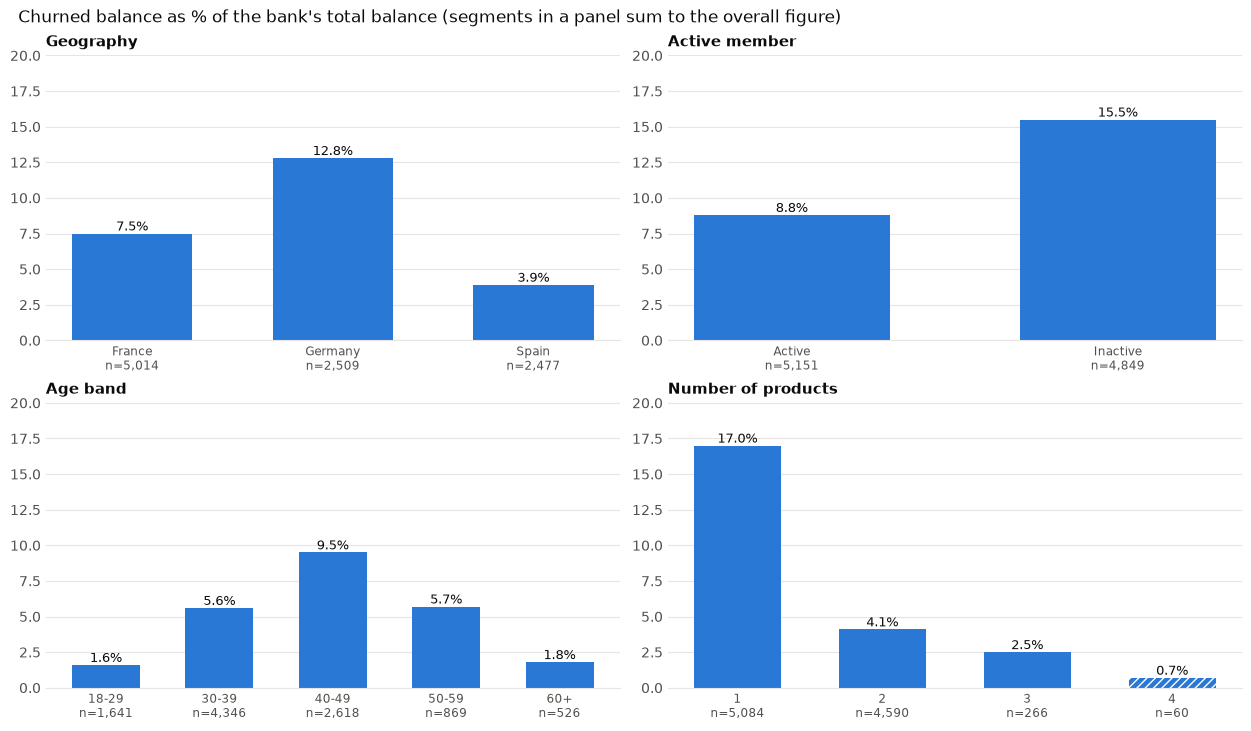

In [8]:
panels(bar, ["Geography", "Active member", "Age band", "Number of products"],
       value="share_of_total_balance", shared_max=True,
       suptitle="Churned balance as % of the bank's total balance (segments in a panel sum to the overall figure)")

## 6. Small segments
Every segment (one-way and two-way) with fewer than 100 customers. Treat these rates as unreliable.

In [9]:
parts = [cust, prod, eng]
one_way = pd.concat([p[["dimension", "segment", "customers", "churners", "churn_rate_pct"]] for p in parts])
two_way = pd.concat([
    geo_act.assign(dimension="Geography x active", segment=geo_act.Geography + " | " + geo_act.activity_label),
    age_prod.assign(dimension="Age band x products", segment=age_prod.age_band + " | " + age_prod.products + " products"),
    geo_zero.assign(dimension="Geography x balance", segment=geo_zero.Geography + " | " + geo_zero.balance_flag),
])[["dimension", "segment", "customers", "churners", "churn_rate_pct"]]
small = pd.concat([one_way, two_way])
display(small[small["customers"] < LOW_N].sort_values("customers").reset_index(drop=True))

,dimension,segment,customers,churners,churn_rate_pct
0,Age band x products,60+ | 3-4 products,23,19,82.6
1,Age band x products,18-29 | 3-4 products,27,17,63.0
2,Number of products,4,60,60,100.0
3,Age band x products,50-59 | 3-4 products,69,68,98.6
4,Age band x products,30-39 | 3-4 products,84,63,75.0


## 7. Statistical checks
Chi-square test of independence between each variable and churn (using the counts from the SQL cuts above), plus a 95% Wilson confidence interval on every segment's churn rate.
With 10,000 customers almost any gap is "significant", so **Cramer's V** (0 = no association, 1 = perfect) is shown as the effect size to compare variables.

In [10]:
from scipy.stats import chi2_contingency, norm

TESTED = ["Geography", "Age band", "Number of products", "Active member", "Zero vs non-zero balance"]
long_all = pd.concat([cust, prod, eng])

rows = []
for dim in TESTED:
    d = long_all[long_all["dimension"] == dim]
    obs = np.column_stack([d["churners"], d["customers"] - d["churners"]]).astype(float)
    chi2, p, dof, exp = chi2_contingency(obs, correction=False)
    rows.append({"variable": dim, "chi2": round(chi2, 1), "dof": dof,
                 "p_value": "<1e-300" if p == 0 else f"{p:.1e}",
                 "cramers_v": round(float(np.sqrt(chi2 / obs.sum())), 3),
                 "min_expected_count": round(float(exp.min()), 1)})
tests = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(tests)

,variable,chi2,dof,p_value,cramers_v,min_expected_count
0,Number of products,1503.6,3,<1e-300,0.388,12.2
1,Age band,1282.7,4,1.9e-276,0.358,107.1
2,Geography,301.3,2,3.8e-66,0.174,504.6
3,Active member,243.8,1,6.0e-55,0.156,987.7
4,Zero vs non-zero balance,149.7,1,2.0e-34,0.122,736.8


In [11]:
def wilson(k, n, z=norm.ppf(0.975)):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - half), 100 * (centre + half)


ci = long_all[long_all["dimension"].isin(TESTED)].copy()
ci[["ci95_low", "ci95_high"]] = [wilson(k, n) for k, n in zip(ci["churners"], ci["customers"])]
ci["ci_width_pts"] = ci["ci95_high"] - ci["ci95_low"]
ci["dimension"] = pd.Categorical(ci["dimension"], TESTED, ordered=True)
ci = ci.sort_values(["dimension", "sort_key"])
display(ci[["dimension", "segment", "customers", "churn_rate_pct", "ci95_low", "ci95_high", "ci_width_pts"]]
        .round(1).reset_index(drop=True))

,dimension,segment,customers,churn_rate_pct,ci95_low,ci95_high,ci_width_pts
0,Geography,France,5014,16.2,15.2,17.2,2.0
1,Geography,Germany,2509,32.4,30.6,34.3,3.7
2,Geography,Spain,2477,16.7,15.3,18.2,2.9
3,Age band,18-29,1641,7.6,6.4,8.9,2.6
4,Age band,30-39,4346,10.9,10.0,11.8,1.9
5,Age band,40-49,2618,30.8,29.0,32.6,3.5
6,Age band,50-59,869,56.0,52.7,59.3,6.6
7,Age band,60+,526,27.9,24.3,31.9,7.6
8,Number of products,1,5084,27.7,26.5,29.0,2.5
9,Number of products,2,4590,7.6,6.9,8.4,1.5


Reading the table: every variable is significant (the products p-value underflows to zero), so the useful comparison is effect size.
By Cramer's V the ranking is number of products (0.39), age band (0.36), geography (0.17), active member (0.16) and zero balance (0.12).
Confidence intervals confirm the small-segment warning: the 4-product rate has an interval of roughly 94% to 100%, and the 3-product interval is about 78% to 87%,
so both are far above the 2-product interval (about 7% to 8%) even after allowing for sampling noise.
Also note that the zero-balance effect is confounded with geography: no German customer has a zero balance.

## Top 5 findings

These are descriptive, one-or-two-variable cuts, not causal effects. Age, products and activity are correlated with each other, so the model stage has to separate them.

1. **Product lever - number of products is the sharpest split.** Customers with 2 products churn at only 7.6%, the lowest of any segment;
   1-product customers churn at 27.7%; customers with 3 products churn at 82.7% and with 4 products at 100%. The same ordering holds inside every age band.
   The 3 and 4 product groups are tiny (266 and 60 customers), so how extreme those rates are is uncertain, but the direction is clear.
2. **Customer lever - age 40-59.** Churn is 7.6% (18-29) and 10.9% (30-39), then jumps to 30.8% (40-49) and 56.0% (50-59), and eases to 27.9% at 60+.
   Ages 40-59 are 35% of customers but 63% of the at-risk balance (116.4M of 185.6M).
3. **Customer lever - Germany.** Germany churns at 32.4% against 16.2% (France) and 16.7% (Spain). It holds 25% of customers but 53% of all balance at risk
   (98.0M of 185.6M). Every German customer has a non-zero balance, so zero-balance customers cannot explain the gap: French non-zero-balance customers churn at only 18.2%.
4. **Engagement lever - inactive members.** Inactive customers churn at 26.9% vs 14.3% for active ones, and hold 63.8% of the at-risk balance.
   It compounds with geography: inactive German members churn at 41.1%, active Spanish members at 10.7%.
5. **Financial framing - balance at risk.** Churned customers held 185.6M of 764.9M total balance, i.e. **24.3% of balance** against a 20.4% customer churn rate,
   because churners hold above-average balances. Customers with 1 product account for 129.7M (70%) of that at-risk balance.

**Also notable.** Women churn more than men (25.1% vs 16.5%). Zero-balance customers churn less (13.8% vs 24.1%), but part of that is mix: there are none in Germany.
**Little or no signal on their own:** credit score (18.6% to 23.7% across all bands, with no clear trend), having a credit card (20.2% vs 20.8%) and tenure (18.9% to 21.3%).

**Rates to treat as unreliable (fewer than 100 customers):** 4 products (n=60, 100%); in the age x products cut, the '3-4 products' cells for
ages 18-29 (n=27), 30-39 (n=84), 50-59 (n=69) and 60+ (n=23). The Germany x zero-balance cell is empty. Section 6 lists them all.

## Actionable levers vs targeting variables

The bank can *change* some of these things and can only *observe* others. That difference decides how each should be used.

**Actionable levers (the bank can influence them):**
- **Number of products.** It has the strongest association with churn (Cramer's V 0.39). The 2-product group churns least, while 1-product customers are an obvious cross-sell group.
  The very high rates at 3-4 products suggest a problem with how those customers are served, not a reason to push more products; this data cannot say which.
- **Active membership.** Inactive customers churn at nearly double the rate (26.9% vs 14.3%, V 0.16) and hold most of the at-risk balance. Re-engagement campaigns are directly in the bank's hands.

**Targeting variables (cannot be changed, but tell you where to look):**
- **Age.** The 40-59 bands carry the highest churn and a large share of at-risk balance (V 0.36). Age is for deciding *who* to prioritise, not something to act on.
- **Geography.** Germany churns about twice as much as France or Spain and holds over half the at-risk balance (V 0.17). It points to where to focus effort and to investigate (pricing, competition, service); the country itself is not a lever.

Caveats before the modelling stage: these are associations, not proven causes. Products, activity, age and geography overlap with each other
(for example, the products effect holds inside every age band, but the Germany and zero-balance effects are entangled), so their separate contributions have to be estimated together in a model.